# Bank Transaction Segmentation
**Muhammad Akhtar Ariq · Exploratory analysis and unsupervised learning**

This notebook develops a reproducible segmentation of bank transactions, from
source-data validation to interpretable cluster profiles and saved model artifacts.
The companion classification notebook learns to reproduce these assignments.

**Run:** install `requirements.txt`, select the project environment, and run all
cells from the repository root. The default source is the public course CSV.
Generated artifacts are overwritten on each execution. `BMLP_DATASET_PATH` can
point to a local copy; `BMLP_OUTPUT_DIR` redirects generated files for an isolated run.

Originally developed as the BMLP final project; this edition replaces the course
exercise template with documented analysis code. The original submission remains
available in Git history.

## 1. Analytical scope and experiment design

**Question:** which groups emerge from the available transaction features?
These are exploratory transaction groups, not verified fraud outcomes or validated
customer personas. An account may contribute multiple transactions.

The reference experiment retains three clusters for continuity with the original
analysis. We also compare 2–9 clusters using inertia and silhouette scores; the
comparison is reported even when it favors a different number of clusters.
Explicit random seeds and ten K-Means initializations make this comparison repeatable.

The original feature representation is retained: numerical features are standardized,
while categorical features use integer label encoding. These category codes impose
artificial distances, especially for location. Therefore the results demonstrate
the workflow rather than establish an optimal segmentation method.

In [1]:
from __future__ import annotations

import hashlib
import json
import os
import platform
from importlib.metadata import version
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import Markdown, display
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import LabelEncoder, StandardScaler

RANDOM_STATE = 42
N_CLUSTERS = 3
N_INITIALIZATIONS = 10
CLUSTER_COUNTS = range(2, 10)
TARGET_COLUMN = "Target"
DATASET_URL = (
    "https://docs.google.com/spreadsheets/d/e/"
    "2PACX-1vTbg5WVW6W3c8SPNUGc3A3AL-AG32TPEQGpdzARfNICMsLFI0LQj0jporhsLCeVhkN5AoRsTkn08AYl/"
    "pub?output=csv"
)
DATASET_SOURCE = os.environ.get("BMLP_DATASET_PATH", DATASET_URL)
OUTPUT_DIR = Path(os.environ.get("BMLP_OUTPUT_DIR", ".")).resolve()
ASSETS_DIR = OUTPUT_DIR / "assets"
REPORTS_DIR = OUTPUT_DIR / "reports"

NUMERICAL_FEATURES = (
    "TransactionAmount", "CustomerAge", "TransactionDuration",
    "LoginAttempts", "AccountBalance",
)
CATEGORICAL_FEATURES = ("TransactionType", "Location", "Channel", "CustomerOccupation")
FEATURE_COLUMNS = (
    "TransactionAmount", "TransactionType", "Location", "Channel", "CustomerAge",
    "CustomerOccupation", "TransactionDuration", "LoginAttempts", "AccountBalance",
)
EXCLUDED_COLUMNS = (
    "TransactionID", "AccountID", "PreviousTransactionDate", "DeviceID",
    "IP Address", "MerchantID", "TransactionDate",
)
AGE_LABELS = ("Muda", "Dewasa", "Tua")

In [2]:
def validate_transactions(frame: pd.DataFrame) -> None:
    """Check the source schema before cleaning, allowing missing values.

    Raises
    ------
    ValueError
        If records are empty, columns are missing/duplicated, a numerical
        feature is nonnumeric, or an infinite value would enter preprocessing.
    """
    required = set(FEATURE_COLUMNS) | set(EXCLUDED_COLUMNS)
    missing = sorted(required - set(frame.columns))
    if missing:
        raise ValueError(f"Source data is missing required columns: {missing}")
    if frame.empty or not frame.columns.is_unique:
        raise ValueError("Source data must contain records and unique column names.")
    for column in NUMERICAL_FEATURES:
        if not pd.api.types.is_numeric_dtype(frame[column]):
            raise ValueError(f"{column} must contain numerical values.")
    if np.isinf(frame[list(NUMERICAL_FEATURES)].to_numpy(dtype=float)).any():
        raise ValueError("Numerical features contain infinite values.")


def filter_iqr_outliers(
    frame: pd.DataFrame, columns: list[str] | tuple[str, ...]
) -> pd.DataFrame:
    """Return a copy after sequential filtering outside 1.5 × IQR fences.

    Quartiles are recalculated on the retained rows for each feature, matching
    the reference workflow; feature order therefore matters. When IQR is zero,
    only values equal to the quartiles remain. Original row indices are retained
    so that transformed features and cluster labels remain aligned.
    """
    filtered = frame.copy()
    for column in columns:
        lower_quartile, upper_quartile = filtered[column].quantile([0.25, 0.75])
        spread = upper_quartile - lower_quartile
        keep = filtered[column].between(
            lower_quartile - 1.5 * spread,
            upper_quartile + 1.5 * spread,
            inclusive="both",
        )
        filtered = filtered.loc[keep].copy()
    return filtered


def encode_features(
    frame: pd.DataFrame,
) -> tuple[pd.DataFrame, StandardScaler, dict[str, LabelEncoder], np.ndarray]:
    """Fit the reference feature representation on already-cleaned records.

    Returns encoded/scaled features, the numerical scaler, fitted category
    encoders, and age quantile edges in original units. The returned state is
    sufficient to reproduce these transformations for known categories.
    Unknown categories and out-of-range ages require an explicit policy before
    applying this research model to new records.
    """
    features = frame.loc[:, FEATURE_COLUMNS].copy()
    encoders = {}
    for column in CATEGORICAL_FEATURES:
        encoder = LabelEncoder()
        features[column] = encoder.fit_transform(features[column])
        encoders[column] = encoder

    scaler = StandardScaler()
    features[list(NUMERICAL_FEATURES)] = scaler.fit_transform(features[list(NUMERICAL_FEATURES)])

    # Quantiles are unchanged by the scaler's monotonic age transformation.
    age_groups, age_edges = pd.qcut(
        frame["CustomerAge"], q=3, labels=list(AGE_LABELS), retbins=True
    )
    age_encoder = LabelEncoder()
    features["AgeGroup"] = age_encoder.fit_transform(age_groups)
    encoders["AgeGroup"] = age_encoder
    return features, scaler, encoders, age_edges

## 2. Source data and quality checks

The source includes amounts, balances, customer attributes, channels, locations,
and transaction identifiers. Identifiers and timestamps are excluded explicitly
rather than selected by substring, making the model's input schema auditable.
Missing records and duplicates are measured before removal.

In [3]:
for directory in (OUTPUT_DIR, ASSETS_DIR, REPORTS_DIR):
    directory.mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid", context="notebook", palette="colorblind")
pd.set_option("display.max_columns", 20)

raw_transactions = pd.read_csv(DATASET_SOURCE)
validate_transactions(raw_transactions)
data_fingerprint = hashlib.sha256(
    raw_transactions.to_csv(index=False).encode("utf-8")
).hexdigest()
display(pd.DataFrame({
    "value": [len(raw_transactions), raw_transactions.shape[1],
              int(raw_transactions.isna().any(axis=1).sum()),
              int(raw_transactions.duplicated().sum())],
}, index=["Source rows", "Source columns", "Rows with missing values", "Duplicate rows"]))
display(raw_transactions.loc[:, FEATURE_COLUMNS].head())
display(raw_transactions[list(NUMERICAL_FEATURES)].describe().round(2))

,value
Source rows,2537
Source columns,16
Rows with missing values,381
Duplicate rows,21


,TransactionAmount,TransactionType,Location,Channel,CustomerAge,CustomerOccupation,TransactionDuration,LoginAttempts,AccountBalance
0,14.09,Debit,San Diego,ATM,70.0,Doctor,81.0,1.0,5112.21
1,376.24,Debit,Houston,ATM,68.0,Doctor,141.0,1.0,13758.91
2,126.29,Debit,Mesa,Online,19.0,Student,56.0,1.0,1122.35
3,184.50,Debit,Raleigh,Online,26.0,Student,25.0,1.0,8569.06
4,13.45,Credit,Atlanta,Online,NaN,Student,198.0,1.0,7429.40


,TransactionAmount,CustomerAge,TransactionDuration,LoginAttempts,AccountBalance
count,2511.00,2519.00,2511.00,2516.00,2510.00
mean,297.66,44.68,119.42,1.12,5113.44
std,292.23,17.84,70.08,0.59,3897.98
min,0.26,18.00,10.00,1.00,101.25
25%,81.31,27.00,63.00,1.00,1504.73
50%,211.36,45.00,112.00,1.00,4734.11
75%,413.10,59.00,161.00,1.00,7672.69
max,1919.11,80.00,300.00,5.00,14977.99


## 3. Exploratory analysis

These plots use the unfiltered source data, so the tails and missing-data effects
remain visible. Correlation describes linear association, not causation.
Transaction amount is compared by occupation to inspect distribution differences,
without treating occupation as an explanation for behavior.

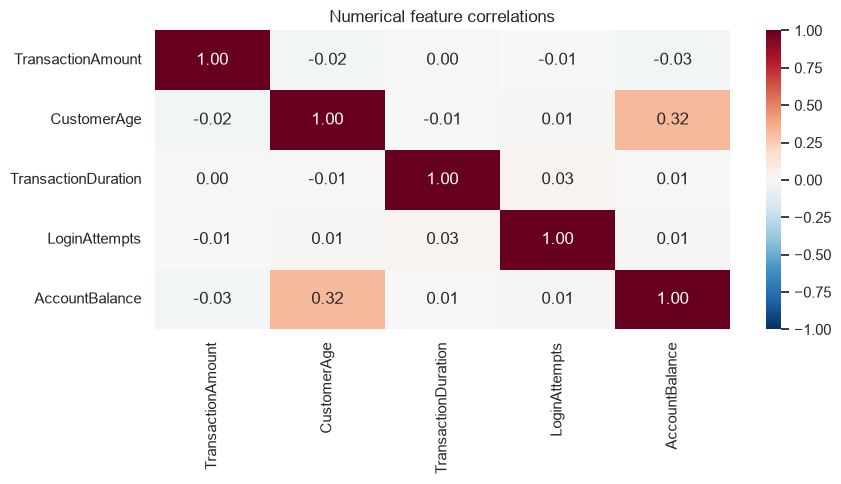

In [4]:
figure, axis = plt.subplots(figsize=(9, 5))
sns.heatmap(
    raw_transactions[list(NUMERICAL_FEATURES)].corr(),
    annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, ax=axis,
)
axis.set_title("Numerical feature correlations")
figure.tight_layout()
figure.savefig(ASSETS_DIR / "correlation-heatmap.png", dpi=160, bbox_inches="tight")
plt.show()
plt.close(figure)

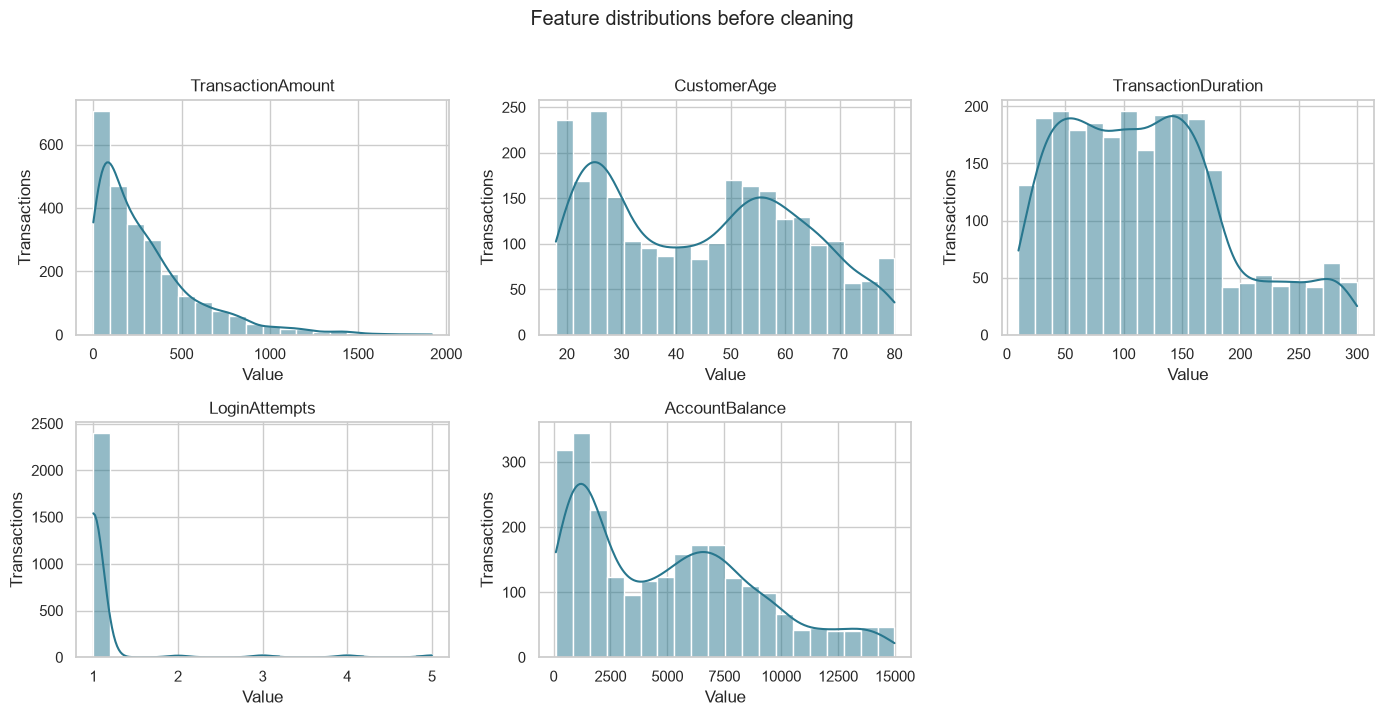

In [5]:
figure, axes = plt.subplots(2, 3, figsize=(14, 7))
for axis, column in zip(axes.flat, NUMERICAL_FEATURES):
    sns.histplot(raw_transactions[column], bins=20, kde=True, ax=axis, color="#28778e")
    axis.set(title=column, xlabel="Value", ylabel="Transactions")
for axis in list(axes.flat)[len(NUMERICAL_FEATURES):]:
    axis.set_visible(False)
figure.suptitle("Feature distributions before cleaning", y=1.02)
figure.tight_layout()
figure.savefig(ASSETS_DIR / "numerical-distributions.png", dpi=160, bbox_inches="tight")
plt.show()
plt.close(figure)

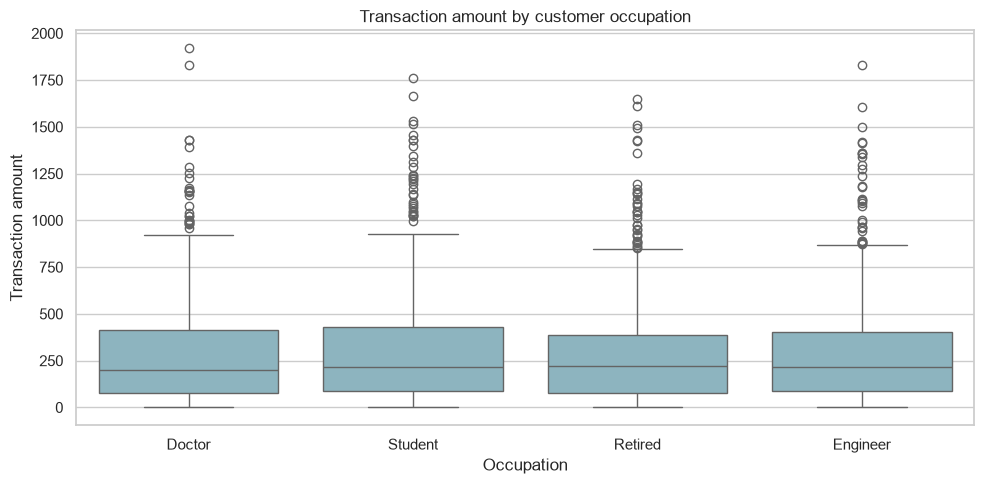

In [6]:
figure, axis = plt.subplots(figsize=(10, 5))
sns.boxplot(
    data=raw_transactions, x="CustomerOccupation", y="TransactionAmount",
    color="#85b9c7", ax=axis,
)
axis.set(title="Transaction amount by customer occupation", xlabel="Occupation", ylabel="Transaction amount")
figure.tight_layout()
figure.savefig(ASSETS_DIR / "transaction-amount-by-occupation.png", dpi=160, bbox_inches="tight")
plt.show()
plt.close(figure)

## 4. Cleaning and feature engineering

The cleaning sequence is retained from the reference analysis: remove incomplete
records, remove exact duplicates, and then apply numerical IQR filters in the
declared feature order. The audit below reports the rows remaining at each stage.

**Tradeoff:** this approach discards potentially informative unusual transactions.
In particular, a zero IQR for `LoginAttempts` can remove every value above one.
This preprocessing would be inappropriate for a fraud-detection claim without
revisiting that decision.

Numerical features are standardized; categorical columns are label-encoded. Age
tertiles retain the original labels: `Muda` (younger), `Dewasa` (middle), and `Tua`
(older). These are relative quantile groups rather than fixed age definitions.

In [7]:
complete_transactions = raw_transactions.dropna().copy()
unique_transactions = complete_transactions.drop_duplicates().copy()
clean_transactions = filter_iqr_outliers(unique_transactions, NUMERICAL_FEATURES)
if len(clean_transactions) <= max(CLUSTER_COUNTS):
    raise ValueError("Too few records remain for the configured cluster-count comparison.")

cleaning_audit = pd.DataFrame({
    "stage": ["Source", "Complete records", "Deduplicated", "IQR filtered"],
    "rows_retained": [len(raw_transactions), len(complete_transactions),
                      len(unique_transactions), len(clean_transactions)],
})
cleaning_audit["rows_removed"] = (
    cleaning_audit["rows_retained"].shift(1) - cleaning_audit["rows_retained"]
).fillna(0).astype(int)
display(cleaning_audit)

features, scaler, category_encoders, age_bin_edges = encode_features(clean_transactions)
if not np.isfinite(features.to_numpy(dtype=float)).all():
    raise ValueError("Prepared features contain missing or nonfinite values.")
display(features.head())
display(features.describe().round(3))

,stage,rows_retained,rows_removed
0,Source,2537,0
1,Complete records,2156,381
2,Deduplicated,2135,21
3,IQR filtered,1945,190


,TransactionAmount,TransactionType,Location,Channel,CustomerAge,CustomerOccupation,TransactionDuration,LoginAttempts,AccountBalance,AgeGroup
0,-1.111922,1,36,0,1.426636,0,-0.541568,0.0,0.002918,2
1,0.546926,1,15,0,1.313889,0,0.308502,0.0,2.216531,2
2,-0.597984,1,23,2,-1.448403,3,-0.895763,0.0,-1.018513,1
3,-0.331350,1,33,2,-1.053790,3,-1.334965,0.0,0.887895,1
5,-0.754364,1,28,0,-1.504776,3,0.747704,0.0,-1.105726,1


,TransactionAmount,TransactionType,Location,Channel,CustomerAge,CustomerOccupation,TransactionDuration,LoginAttempts,AccountBalance,AgeGroup
count,1945.000,1945.000,1945.000,1945.000,1945.000,1945.000,1945.000,1945.0,1945.000,1945.000
mean,-0.000,0.772,21.300,0.977,-0.000,1.503,0.000,0.0,-0.000,0.999
std,1.000,0.420,12.329,0.804,1.000,1.136,1.000,0.0,1.000,0.810
min,-1.175,0.000,0.000,0.000,-1.505,0.000,-1.547,0.0,-1.280,0.000
25%,-0.815,1.000,11.000,0.000,-0.997,0.000,-0.797,0.0,-0.925,0.000
50%,-0.262,1.000,21.000,1.000,0.017,1.000,-0.117,0.0,-0.104,1.000
75%,0.539,1.000,32.000,2.000,0.807,3.000,0.606,0.0,0.655,2.000
max,2.961,1.000,42.000,2.000,1.990,3.000,2.561,0.0,2.529,2.000


## 5. Compare cluster counts and fit the reference model

Inertia decreases as more clusters are added; the silhouette score measures how
well separated the groups are, with higher values preferred. The same features,
seed, and initialization count are used for every candidate.

The three-cluster candidate is retained as the reference experiment even when
another candidate has a higher silhouette score. Cluster numbers are arbitrary
identifiers and can be permuted after retraining.

In [8]:
candidate_models = {}
candidate_metrics = []
for cluster_count in CLUSTER_COUNTS:
    candidate = KMeans(
        n_clusters=cluster_count, random_state=RANDOM_STATE,
        n_init=N_INITIALIZATIONS,
    ).fit(features)
    candidate_models[cluster_count] = candidate
    candidate_metrics.append({
        "clusters": cluster_count,
        "inertia": candidate.inertia_,
        "silhouette": silhouette_score(features, candidate.labels_),
    })

clustering_metrics = pd.DataFrame(candidate_metrics).set_index("clusters")
cluster_model = candidate_models[N_CLUSTERS]
cluster_labels = pd.Series(cluster_model.labels_, index=features.index, name=TARGET_COLUMN)
reference_silhouette = clustering_metrics.loc[N_CLUSTERS, "silhouette"]
best_cluster_count = int(clustering_metrics["silhouette"].idxmax())
display(clustering_metrics.round(4))
display(cluster_labels.value_counts().sort_index().rename("transactions").to_frame())

,inertia,silhouette
clusters,,
2,87890.7697,0.5720
3,46195.9566,0.4947
4,31025.0204,0.4446
5,24594.8005,0.3910
6,21308.2026,0.3400
7,18930.8005,0.3047
8,17632.3071,0.2699
9,16750.1890,0.2414


,transactions
Target,
0,647
1,637
2,661


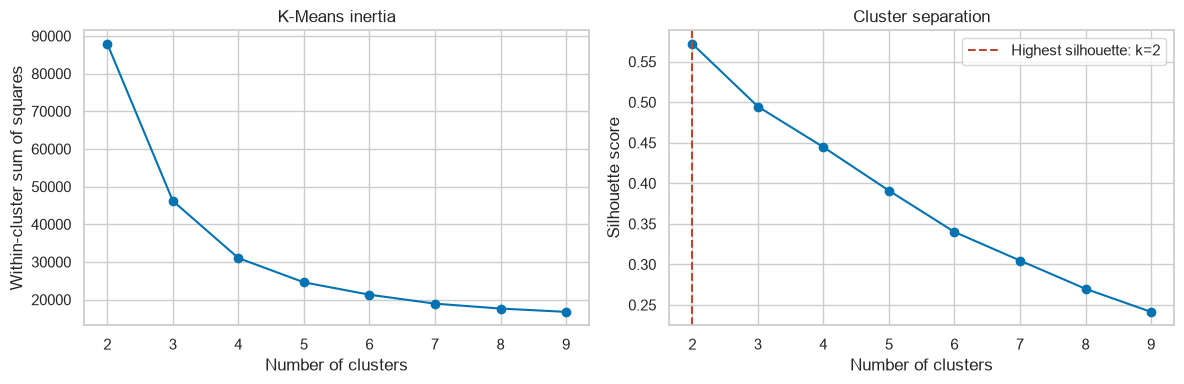

In [9]:
figure, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(clustering_metrics.index, clustering_metrics["inertia"], marker="o")
axes[0].set(title="K-Means inertia", xlabel="Number of clusters", ylabel="Within-cluster sum of squares")
axes[1].plot(clustering_metrics.index, clustering_metrics["silhouette"], marker="o")
axes[1].axvline(best_cluster_count, color="#b34a32", linestyle="--", label=f"Highest silhouette: k={best_cluster_count}")
axes[1].set(title="Cluster separation", xlabel="Number of clusters", ylabel="Silhouette score")
axes[1].legend()
for axis in axes:
    axis.set_xticks(list(CLUSTER_COUNTS))
figure.tight_layout()
figure.savefig(ASSETS_DIR / "kmeans-elbow.png", dpi=160, bbox_inches="tight")
plt.show()
plt.close(figure)

## 6. PCA projection and a reduced-space comparison

The scatter plot projects the reference model's assignments into two principal
components; it does not refit those assignments. Each cluster has a distinct color.
Explained variance describes how much of the prepared feature variation is visible.

A separate K-Means model is then fitted in this reduced space. Its silhouette is
reported in both the PCA space and the original prepared space, explicitly naming
the distance representation rather than comparing unlike scores silently.

,PC1,PC2
Location,1.0000,-0.0016
CustomerAge,-0.0028,-0.4203
TransactionDuration,-0.0027,0.0295
AgeGroup,-0.0010,-0.0055
TransactionAmount,0.0007,0.0448
CustomerOccupation,0.0006,0.7001
TransactionType,-0.0005,0.0046
Channel,0.0004,0.0102
AccountBalance,0.0000,-0.5746
LoginAttempts,0.0000,0.0000


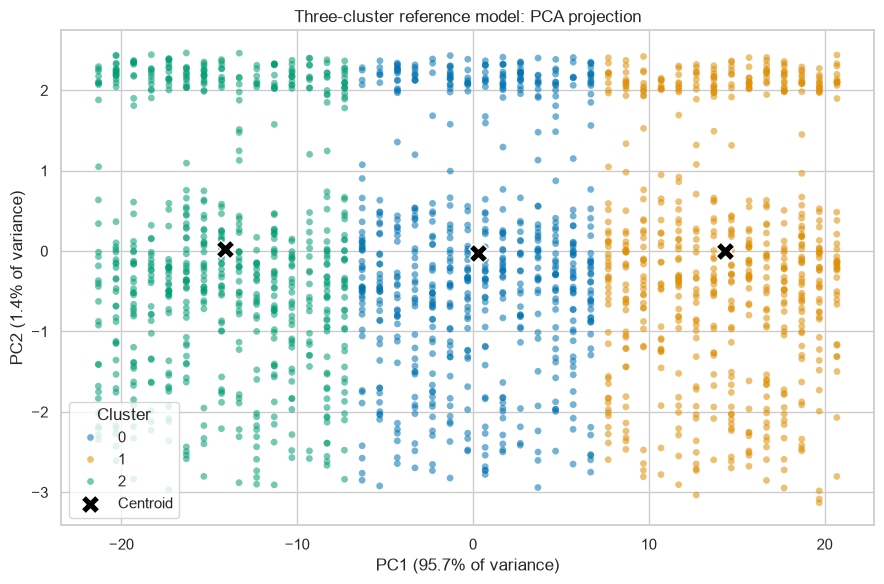

,value
Variance retained by two PCs,0.9711
Reference labels: silhouette in prepared space,0.4947
PCA model labels: silhouette in PCA space,0.5519
PCA model labels: silhouette in prepared space,0.4957


In [10]:
pca_transformer = PCA(n_components=2, svd_solver="full")
projected_array = pca_transformer.fit_transform(features)
projected_features = pd.DataFrame(projected_array, index=features.index, columns=["PC1", "PC2"])
centroid_frame = pd.DataFrame(cluster_model.cluster_centers_, columns=features.columns)
projected_centroids = pca_transformer.transform(centroid_frame)

figure, axis = plt.subplots(figsize=(9, 6))
palette = dict(zip(range(N_CLUSTERS), sns.color_palette("colorblind", N_CLUSTERS)))
sns.scatterplot(
    data=projected_features.assign(Cluster=cluster_labels), x="PC1", y="PC2",
    hue="Cluster", palette=palette, alpha=0.55, s=24, linewidth=0, ax=axis,
)
axis.scatter(projected_centroids[:, 0], projected_centroids[:, 1], marker="X",
             s=180, c="black", edgecolors="white", label="Centroid")
variance = pca_transformer.explained_variance_ratio_
pca_loadings = pd.DataFrame(
    pca_transformer.components_.T, index=features.columns, columns=["PC1", "PC2"]
)
display(pca_loadings.sort_values("PC1", key=lambda values: values.abs(), ascending=False).round(4))
axis.set(title="Three-cluster reference model: PCA projection",
         xlabel=f"PC1 ({variance[0]:.1%} of variance)", ylabel=f"PC2 ({variance[1]:.1%} of variance)")
axis.legend(title="Cluster")
figure.tight_layout()
figure.savefig(ASSETS_DIR / "pca-clusters.png", dpi=160, bbox_inches="tight")
plt.show()
plt.close(figure)

pca_cluster_model = KMeans(
    n_clusters=N_CLUSTERS, random_state=RANDOM_STATE, n_init=N_INITIALIZATIONS
).fit(projected_features)
display(pd.Series({
    "Variance retained by two PCs": variance.sum(),
    "Reference labels: silhouette in prepared space": reference_silhouette,
    "PCA model labels: silhouette in PCA space": silhouette_score(projected_features, pca_cluster_model.labels_),
    "PCA model labels: silhouette in prepared space": silhouette_score(features, pca_cluster_model.labels_),
}).rename("value").to_frame().round(4))

## 7. Interpret clusters in original units

The inverse-transformed dataset restores numerical values and category labels
while retaining the exact row/target alignment used in training. Both numerical
ranges and modal categories are displayed. The means alone do not justify
labels such as “high-value” or “tech-savvy”; use the measured differences instead.

In [11]:
encoded_export = features.assign(**{TARGET_COLUMN: cluster_labels})
readable_export = encoded_export.copy()
readable_export[list(NUMERICAL_FEATURES)] = scaler.inverse_transform(features[list(NUMERICAL_FEATURES)])
for column, encoder in category_encoders.items():
    readable_export[column] = encoder.inverse_transform(features[column].to_numpy(dtype=int))

numerical_profiles = readable_export.groupby(TARGET_COLUMN)[list(NUMERICAL_FEATURES)].agg(["mean", "min", "max"])
categorical_profiles = readable_export.groupby(TARGET_COLUMN)[[*CATEGORICAL_FEATURES, "AgeGroup"]].agg(
    lambda values: values.mode().iloc[0]
)
cluster_summary = readable_export.groupby(TARGET_COLUMN)[list(NUMERICAL_FEATURES)].mean()
cluster_summary.insert(0, "transactions", cluster_labels.value_counts().sort_index())

display(cluster_summary.round(2))
display(numerical_profiles.round(2).T)
display(categorical_profiles.T)

np.testing.assert_allclose(readable_export[list(NUMERICAL_FEATURES)], clean_transactions[list(NUMERICAL_FEATURES)])
assert readable_export[TARGET_COLUMN].equals(encoded_export[TARGET_COLUMN])

,transactions,TransactionAmount,CustomerAge,TransactionDuration,LoginAttempts,AccountBalance
Target,,,,,,
0,647,260.97,45.52,119.94,1.0,5100.88
1,637,257.84,43.78,117.26,1.0,5120.89
2,661,251.83,44.77,120.41,1.0,5081.40


Target                           0         1         2
TransactionAmount   mean    260.97    257.84    251.83
                    min       0.26      1.41      0.32
                    max     890.24    889.01    903.19
CustomerAge         mean     45.52     43.78     44.77
                    min      18.00     18.00     18.00
                    max      80.00     80.00     80.00
TransactionDuration mean    119.94    117.26    120.41
                    min      10.00     10.00     10.00
                    max     299.00    296.00    300.00
LoginAttempts       mean      1.00      1.00      1.00
                    min       1.00      1.00      1.00
                    max       1.00      1.00      1.00
AccountBalance      mean   5100.88   5120.89   5081.40
                    min     112.76    102.20    117.98
                    max   14798.10  14977.99  14942.78

Target,0,1,2
TransactionType,Debit,Debit,Debit
Location,Oklahoma City,Tucson,Charlotte
Channel,Branch,Branch,Branch
CustomerOccupation,Engineer,Student,Doctor
AgeGroup,Dewasa,Muda,Muda


## 8. Export data, model state, and experiment provenance

The two CSV names remain compatible with the companion notebook. Existing `.h5`
filenames are retained, but their contents are **Joblib-serialized scikit-learn
estimators**, not HDF5 or neural-network models. The additional `.joblib` files
store the fitted preprocessing state and PCA transformer that were absent from
the original submission. Load serialized artifacts only from a trusted source.

`reports/` records candidate scores, cleaning counts, profiles, source fingerprint,
and dependency versions. The preprocessing bundle includes feature order, category
encoders, numerical scaler, and age-bin boundaries. It is research state, not an
automatic production policy for unseen categories or anomalous new records.

In [12]:
encoded_export.to_csv(OUTPUT_DIR / "data_clustering.csv", index=False)
readable_export.to_csv(OUTPUT_DIR / "data_clustering_inverse.csv", index=False)
joblib.dump(cluster_model, OUTPUT_DIR / "model_clustering.h5")
joblib.dump(pca_cluster_model, OUTPUT_DIR / "PCA_model_clustering.h5")
joblib.dump(pca_transformer, OUTPUT_DIR / "pca_transformer.joblib")
joblib.dump({
    "scaler": scaler,
    "category_encoders": category_encoders,
    "age_bin_edges": age_bin_edges,
    "age_labels": AGE_LABELS,
    "numerical_features": NUMERICAL_FEATURES,
    "categorical_features": CATEGORICAL_FEATURES,
    "feature_columns": features.columns.tolist(),
}, OUTPUT_DIR / "clustering_preprocessing.joblib")

clustering_metrics.to_csv(REPORTS_DIR / "clustering_metrics.csv")
cleaning_audit.to_csv(REPORTS_DIR / "cleaning_audit.csv", index=False)
cluster_summary.to_csv(REPORTS_DIR / "cluster_summary.csv")
numerical_profiles.to_csv(REPORTS_DIR / "cluster_numerical_profiles.csv")
categorical_profiles.to_csv(REPORTS_DIR / "cluster_categorical_profiles.csv")
clustering_metadata = {
    "source": DATASET_SOURCE,
    "source_dataframe_sha256": data_fingerprint,
    "source_rows": len(raw_transactions),
    "retained_rows": len(features),
    "feature_columns": features.columns.tolist(),
    "random_state": RANDOM_STATE,
    "kmeans_initializations": N_INITIALIZATIONS,
    "reference_clusters": N_CLUSTERS,
    "highest_silhouette_clusters": best_cluster_count,
    "reference_silhouette": float(reference_silhouette),
    "pca_explained_variance_ratio": variance.tolist(),
    "python": platform.python_version(),
    "versions": {package: version(package) for package in
                 ("numpy", "pandas", "scikit-learn", "matplotlib", "seaborn", "joblib")},
}
(REPORTS_DIR / "clustering_metadata.json").write_text(
    json.dumps(clustering_metadata, indent=2) + "\n", encoding="utf-8"
)
display(Markdown(
    f"**Run complete:** {len(raw_transactions):,} source rows → {len(features):,} retained rows; "
    f"reference silhouette **{reference_silhouette:.4f}**. The strongest silhouette candidate is "
    f"**k={best_cluster_count}**. Datasets, model state, figures, and reports are saved."
))

**Run complete:** 2,537 source rows → 1,945 retained rows; reference silhouette **0.4947**. The strongest silhouette candidate is **k=2**. Datasets, model state, figures, and reports are saved.

## 9. Interpretation limits and next steps

- This is full-dataset exploratory clustering. Its labels are later reused as a
  supervised target; downstream classifier accuracy measures label agreement.
- Integer category codes can dominate Euclidean distances. Compare one-hot or
  mixed-type distance representations before using the segmentation operationally.
- Outlier removal discards unusual behavior, and age grouping repeats information
  already present in age. Both choices should be challenged in a follow-up study.
- PCA plots compress the representation and cannot independently validate cluster
  quality. Stability across resamples and alternative representations is untested.
- If future transaction prediction is the goal, freeze preprocessing and clustering
  on historical training data, handle unseen categories, and evaluate on later data.

Continue with the companion classification notebook to compare how accurately
supervised estimators reproduce the reference cluster assignments.